### Load libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load dataset Student Performance Dataset

In [3]:
student_data = pd.read_csv("../data/raw/student_data.csv")

### First look on data

In [4]:
student_data.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Possible outlier: absences

The absences column shows a sharp gap between the 75th percentile and the maximum value:

25% — 0
50% (median) — 4
75% — 8
max — 75

Most students have 8 or fewer absences, but the maximum value (75) is nearly 10x higher than the 75th percentile. This suggests one or more students with an unusually high number of absences compared to the rest of the dataset. No action taken yet — will investigate further with a boxplot and decide how to handle it (keep, remove, or flag) during the data cleaning step.

In [5]:
student_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [6]:
student_data.shape

(395, 33)

In [7]:
student_data.select_dtypes(include='int64').columns

Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')

In [8]:
student_data.head(15)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


## Dataset Overview

### **Dataset Size**
The dataset contains **(395, 33)** entries.

---

## Column Summary

### **List of Columns**
## Column Descriptions

- **school** — student's school (GP or MS)
- **sex** — student's gender (M/F)
- **age** — student's age in years
- **address** — home address type (urban/rural)
- **famsize** — family size (≤3 or >3)
- **Pstatus** — parents' cohabitation status
- **Medu** — mother's education level
- **Fedu** — father's education level
- **Mjob** — mother's job
- **Fjob** — father's job
- **reason** — reason for choosing the school
- **guardian** — student's legal guardian
- **traveltime** — home-to-school travel time
- **studytime** — weekly study time
- **failures** — number of past class failures
- **schoolsup** — extra educational support
- **famsup** — family educational support
- **paid** — extra paid classes
- **activities** — extracurricular activities
- **nursery** — attended nursery school
- **higher** — wants higher education
- **internet** — internet access at home
- **romantic** — in a romantic relationship
- **famrel** — family relationship quality
- **freetime** — free time after school
- **goout** — going out with friends
- **Dalc** — workday alcohol consumption
- **Walc** — weekend alcohol consumption
- **health** — current health status
- **absences** — number of school absences
- **G1** — first period grade
- **G2** — second period grade
- **G3** — final grade


---

##  Data Types Overview

### **Columns by Data Type**

#### **Numeric Columns (16 total)**
- **age**
- **Medu**
- **Fedu**
- **traveltime**
- **studytime**
- **failures**
- **famrel**
- **freetime**
- **goout**
- **Dalc**
- **Walc**
- **health**
- **absences**
- **G1**
- **G2**
- **G3**

#### **Categorical Columns (17 total)**

- **school**
- **sex**
- **address**
- **famsize**
- **Pstatus**
- **Mjob**
- **Fjob**
- **reason**
- **guardian**
- **schoolsup**
- **famsup**
- **paid**
- **activities**
- **nursery**
- **higher**
- **internet**
- **romantic**

---

##  Additional Notes
- The dataset appears clean and well‑structured.
- No missing value analysis has been performed.
- No distribution analysis has been performed.
- Boxplot confirmed multiple outliers beyond ~20 absences, including one extreme case at 75 — this appears to be a genuine pattern (a subset of students with high absenteeism) rather than a single data entry error.
- The dataset contains a balanced mix of numeric and categorical features.


### Check nulls

In [9]:
student_data.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### Check duplicates

In [10]:
student_data.duplicated().sum()

np.int64(0)

### Make boxplot

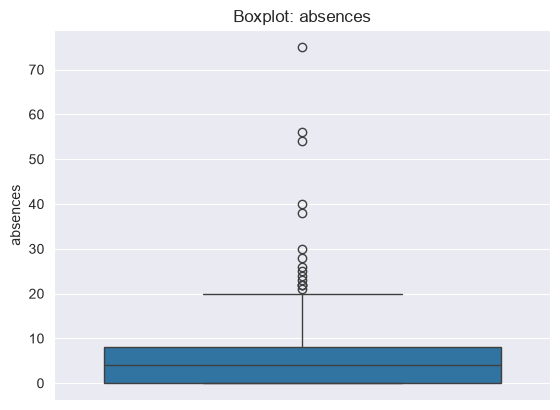

In [11]:
sns.boxplot(y=student_data['absences'])
plt.title('Boxplot: absences')
plt.show()

Boxplot confirms multiple outliers beyond ~20 absences, including one extreme case at 75 — this appears to be a genuine pattern (a subset of students with high absenteeism) rather than a single data entry error.

In [12]:
Q1 = student_data['absences'].quantile(0.25)
Q3 = student_data['absences'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}, upper_bound={upper_bound}")

Q1=0.0, Q3=8.0, IQR=8.0, upper_bound=20.0


### Make flag of absences

In [13]:
student_data['high_absences_flag'] = student_data['absences'] > upper_bound

### Count people with many absences and with not many absences

In [14]:
student_data['high_absences_flag'].value_counts()

high_absences_flag
False    380
True      15
Name: count, dtype: int64

Analysis of absences showed that a threshold of 20 (based on the Q3 + 1.5×IQR rule) separates 96% of students with a typical number of absences from 4% (15 students) with an anomalously high number.

Although this group is small, 15 students is not a single data error but a consistent subgroup. Therefore, it was decided not to remove these rows, but to create a binary feature, high_absences_flag.

This will allow further exploration during EDA of which factors (academic performance, health, family situation, etc.) are characteristic of this specific group, without distorting the overall distribution of absences by removing data.

In [15]:
student_data.isnull().sum().sum()

np.int64(0)

In [16]:
student_data.duplicated().sum()

np.int64(0)

In [17]:
student_data.to_csv('../data/processed/cleaned.csv', index=False)

### Make histplot

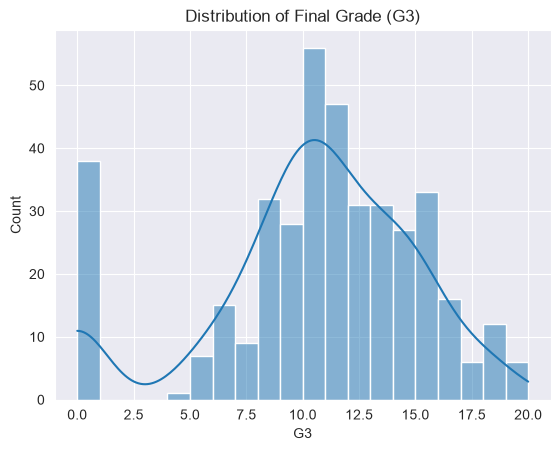

In [18]:
sns.histplot(data=student_data, x='G3', bins=20, kde=True)
plt.title('Distribution of Final Grade (G3)')
plt.show()

### Distribution of G3
The distribution is roughly bell-shaped for most students, centered around 10-12. However, there is a distinct spike of ~38 students with G3=0 — this likely represents students who did not take or complete the final exam, rather than genuinely poor performance. This group should be considered separately during modeling, as it may distort results if treated as a regular low score.

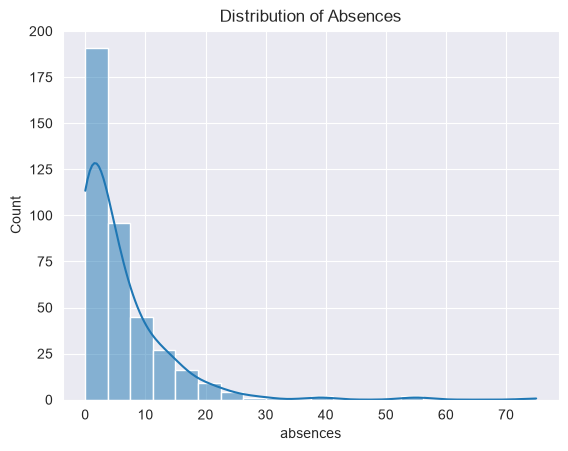

In [19]:
sns.histplot(data=student_data, x='absences', bins=20, kde=True)
plt.title('Distribution of Absences')
plt.show()

### Distribution of Absences
Strongly right-skewed: most students have very few absences (0-5), with a long tail extending to 75. This confirms the pattern already identified via the boxplot and IQR analysis, and supports the earlier decision to flag rather than remove the high-absence subgroup.

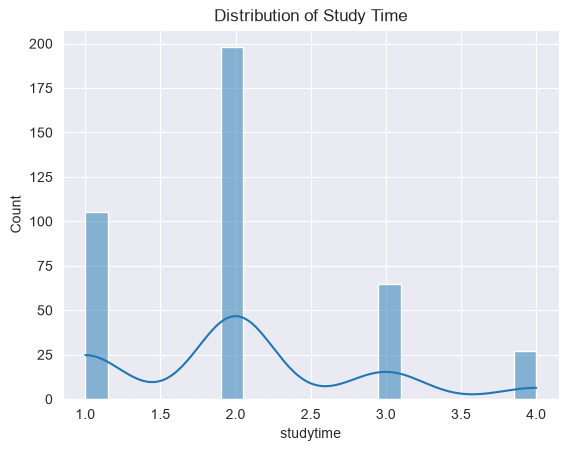

In [20]:
sns.histplot(data=student_data, x='studytime', bins=20, kde=True)
plt.title('Distribution of Study Time')
plt.show()

### Distribution of Study Time
Studytime is a discrete/ordinal variable (values 1-4), not continuous, so the KDE curve is somewhat misleading here. Most students fall into category 2 (moderate study time). A countplot would represent this variable more accurately than a histogram.

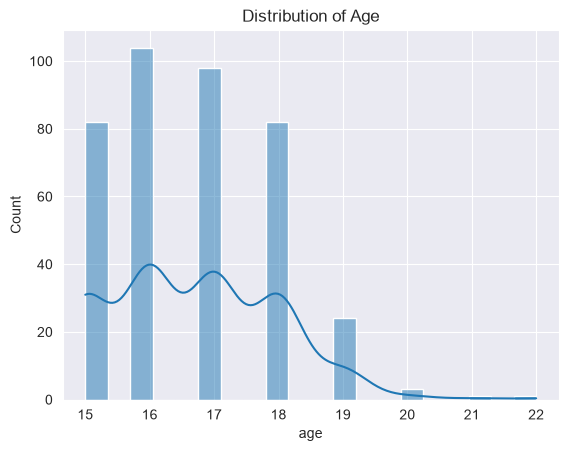

In [21]:
sns.histplot(data=student_data, x='age', bins=20, kde=True)
plt.title('Distribution of Age')
plt.show()

### Distribution of Age
Most students are between 15 and 18 years old, consistent with a secondary school dataset. A small tail extends to 19-22, likely representing students who repeated a grade — worth cross-checking against the `failures` column.

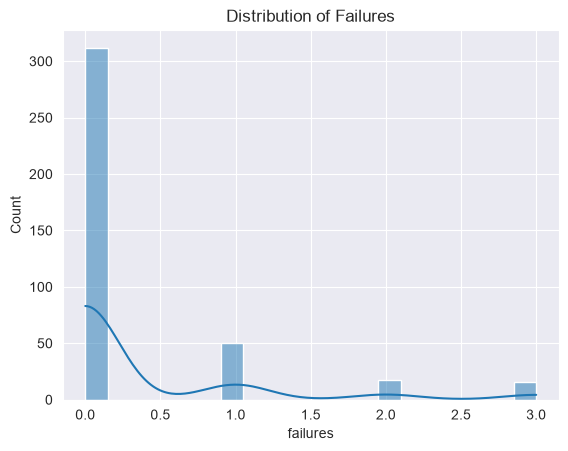

In [22]:
sns.histplot(data=student_data, x='failures', bins=20, kde=True)
plt.title('Distribution of Failures')
plt.show()

### Distribution of Failures
Heavily concentrated at 0 (~310 of 395 students), with a small number of students having 1-3 past failures. Like studytime, this is a discrete variable better suited to a countplot than a histogram — the KDE curve overstates continuity that isn't really there.

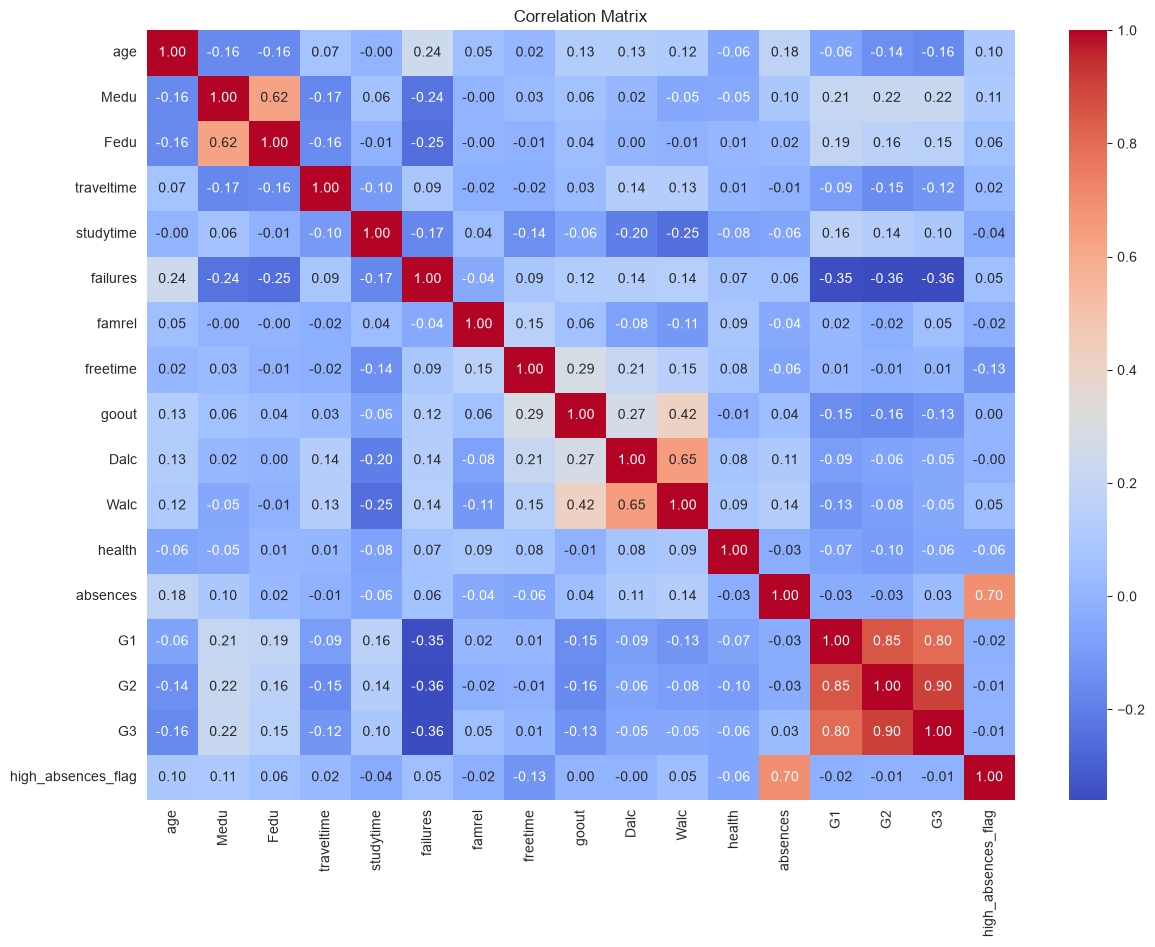

In [33]:
correlation_matrix = student_data.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.savefig('../images/correlation_matrix.png', bbox_inches='tight')
plt.title('Correlation Matrix')
plt.show()

### Correlation Matrix — Key Findings

**Expected relationships confirmed:**
- G1 and G2 show very strong correlation with G3 (0.80 and 0.90 respectively) — as expected, since they are prior period grades for the same students. This confirms the earlier concern about potential data leakage; G1/G2 may need to be excluded or handled carefully during modeling.
- `failures` shows a moderate negative correlation with G3 (-0.36) — more past failures are associated with lower final grades.
- `age` shows only a weak negative correlation with G3 (-0.16).

**Multicollinearity between features (not directly related to G3, but worth noting for modeling):**
- Medu and Fedu (parents' education levels) are moderately correlated (0.62).
- Dalc and Walc (weekday/weekend alcohol consumption) are strongly correlated (0.65).
- goout and Walc are moderately correlated (0.42).

**Unexpected finding:**
- `high_absences_flag` correlates strongly with `absences` (0.70, as expected since it's derived from it), but shows almost no linear correlation with G3 (-0.01). This contradicts the intuitive assumption that high absenteeism leads to lower grades. However, since `high_absences_flag` is binary, linear correlation may not fully capture its relationship with G3 — this will be re-examined with a boxplot comparison between groups.

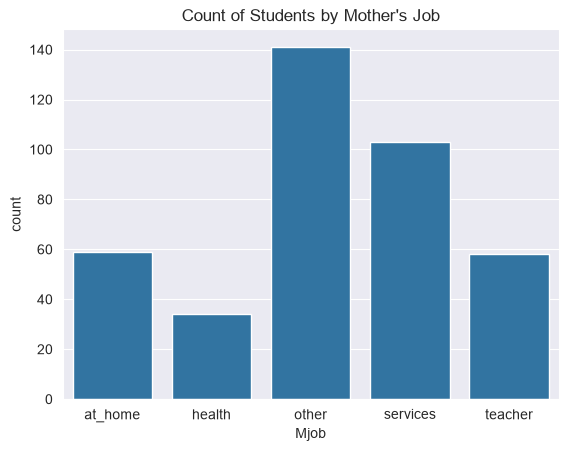

In [24]:
sns.countplot(data=student_data, x='Mjob')
plt.title('Count of Students by Mother\'s Job')
plt.show()

### Mjob distribution
Mother's job is unevenly distributed: 'other' (~140) and 'services' (~103) are the most common categories, while 'health' is the smallest (~34 students). Conclusions involving the 'health' subgroup should be treated with caution due to the small sample size.

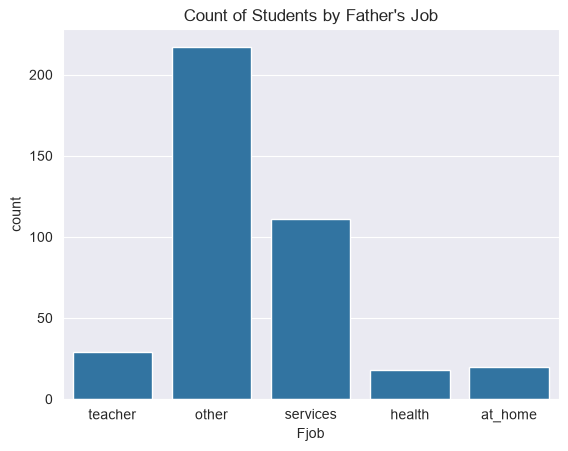

In [25]:
sns.countplot(data=student_data, x='Fjob')
plt.title('Count of Students by Father\'s Job')
plt.show()

### Fjob distribution
Father's job shows a strong imbalance: 'other' accounts for more than half of all students (~217), while 'teacher', 'health', and 'at_home' each represent fewer than 30 students. This matches the "imbalanced category features" warning noted in the dataset description — comparisons involving these small groups will be statistically less reliable.

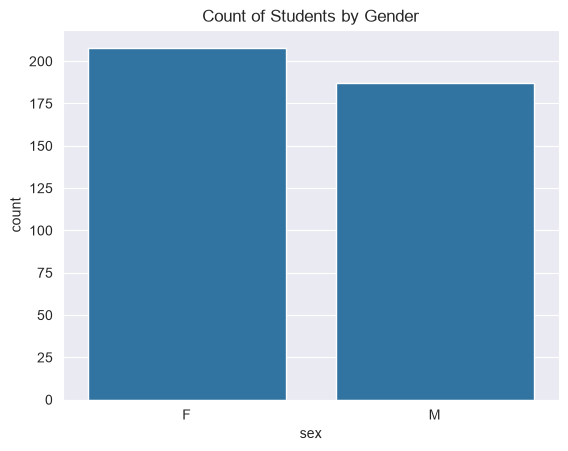

In [26]:
sns.countplot(data=student_data, x='sex')
plt.title('Count of Students by Gender')
plt.show()

### Sex distribution
Fairly balanced: 208 female and 187 male students. No major imbalance concern here.

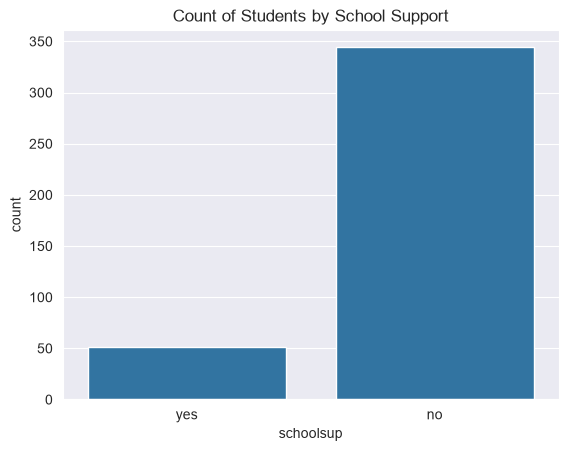

In [27]:
sns.countplot(data=student_data, x='schoolsup')
plt.title('Count of Students by School Support')
plt.show()

### School support distribution
Strongly imbalanced: only ~50 students (13%) received extra school support (schoolsup='yes'), compared to ~345 without it. Any comparison involving this group should be interpreted cautiously.

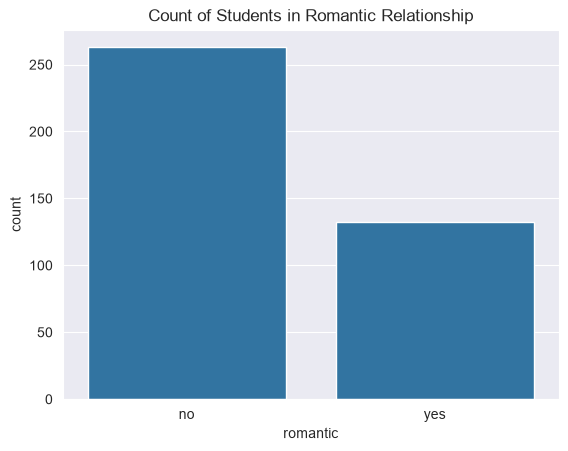

In [28]:
sns.countplot(data=student_data, x='romantic')
plt.title('Count of Students in Romantic Relationship')
plt.show()

### Romantic relationship distribution
Moderately imbalanced: ~265 students are not in a relationship, compared to ~130 who are.

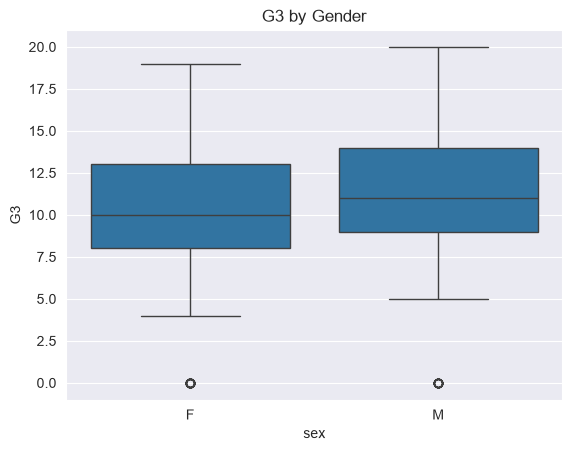

In [29]:
sns.boxplot(data=student_data, x='sex', y='G3')
plt.title('G3 by Gender')
plt.show()

### G3 by Gender
Male students show a slightly higher median G3 (~11) compared to female students (~10), with similar spread (IQR) in both groups. The difference is small, not dramatic. Both groups contain outliers at G3=0.

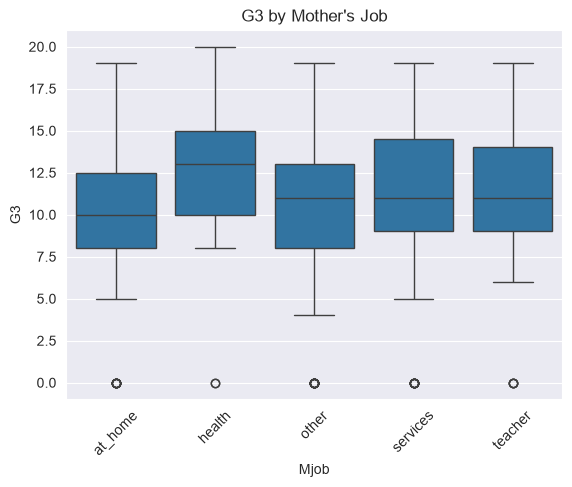

In [30]:
sns.boxplot(data=student_data, x='Mjob', y='G3')
plt.title('G3 by Mother\'s Job')
plt.xticks(rotation=45)
plt.show()

### G3 by Mother's Job
Students whose mothers work in health show the highest median G3 (~13), while students with 'at_home' mothers show one of the lowest (~10). Note: the 'health' group is small (~34 students), so this comparison should be interpreted cautiously.

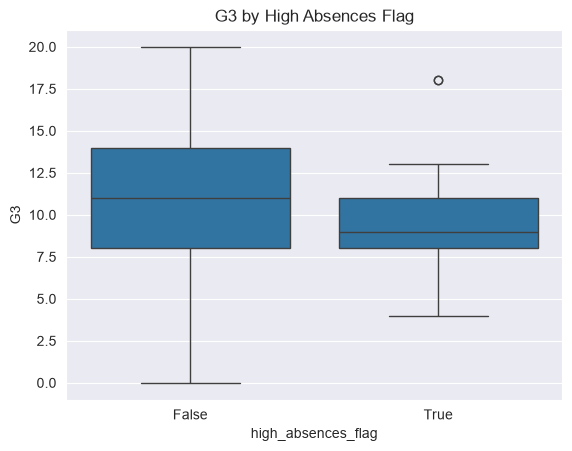

In [34]:
sns.boxplot(data=student_data, x='high_absences_flag', y='G3')
plt.title('G3 by High Absences Flag')
plt.savefig('../images/g3_by_absences_flag.png', bbox_inches='tight')
plt.show()

### G3 by High Absences Flag
Students with high absences show a lower median G3 (~9) compared to those with typical absences (~11), and a notably narrower spread. This contradicts the earlier correlation matrix result (-0.01), which suggested almost no relationship — a reminder that linear correlation can understate relationships involving binary or small-group features. One high-absence student still achieved a strong grade (~18), shown as an outlier.

**Note for modeling:** G3=0 appears across multiple groups and likely represents students who did not complete the final exam rather than a genuine low score. This should be addressed before modeling — e.g., by excluding these rows from the training data.